# 04.10 · Regularisation: Ridge and Lasso

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/04-trustworthy-models/10-regularisation/lesson.ipynb)

Read the [README](README.md) first and do the penalised-loss comparison on paper. This notebook checks it, draws how the slope shrinks as the penalty grows, then uses Lasso to throw away noise columns on the 20-customer table and features on the real churn data.

## 1. Penalised loss by hand

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

x = np.array([2, 4, 6, 8, 10.])            # visits last month
y = np.array([50, 80, 90, 130, 150.])      # spend next month, £
X5 = x.reshape(-1, 1)

def sse(m, c):
    return ((y - (m * x + c)) ** 2).sum()

for m, c in [(12.5, 25), (12, 28)]:
    print(f"m={m:<5} c={c:<3} SSE={sse(m, c):6.1f}   "
          f"Ridge loss (α=1) = SSE + m² = {sse(m, c) + m**2:7.2f}   "
          f"Lasso loss (α=20) = SSE/10 + 20|m| = {sse(m, c) / 10 + 20 * abs(m):6.1f}")

m=12.5  c=25  SSE= 150.0   Ridge loss (α=1) = SSE + m² =  306.25   Lasso loss (α=20) = SSE/10 + 20|m| =  265.0
m=12    c=28  SSE= 160.0   Ridge loss (α=1) = SSE + m² =  304.00   Lasso loss (α=20) = SSE/10 + 20|m| =  256.0


Without a penalty, (12.5, 25) wins (SSE 150 < 160). With Ridge α = 1 the smaller slope wins (304 < 306.25). With Lasso α = 20 the smaller slope wins too (256 < 265). The penalty changed the answer in favour of a flatter line.

## 2. The exact Ridge and Lasso solutions

For one feature both have a closed form you can check by hand (see the README):

- Ridge: $m = \dfrac{S_{xy}}{S_{xx} + \alpha}$ with $S_{xy} = 500$, $S_{xx} = 40$.
- Lasso (scikit-learn's scaling): $m = \dfrac{S_{xy}/n - \alpha}{S_{xx}/n}$, or 0 if that is negative.

In [2]:
from sklearn.linear_model import Ridge, Lasso, LinearRegression
for a in [1, 10, 40]:
    r = Ridge(alpha=a).fit(X5, y)
    print(f"Ridge α={a:>3}: formula m = {500 / (40 + a):6.3f}   sklearn m = {r.coef_[0]:6.3f}, c = {r.intercept_:6.2f}")
for a in [1, 20, 50, 100]:
    l = Lasso(alpha=a).fit(X5, y)
    print(f"Lasso α={a:>3}: formula m = {max(0, (100 - a) / 8):6.3f}   sklearn m = {l.coef_[0]:6.3f}, c = {l.intercept_:6.2f}")

Ridge α=  1: formula m = 12.195   sklearn m = 12.195, c =  26.83
Ridge α= 10: formula m = 10.000   sklearn m = 10.000, c =  40.00
Ridge α= 40: formula m =  6.250   sklearn m =  6.250, c =  62.50
Lasso α=  1: formula m = 12.375   sklearn m = 12.375, c =  25.75
Lasso α= 20: formula m = 10.000   sklearn m = 10.000, c =  40.00
Lasso α= 50: formula m =  6.250   sklearn m =  6.250, c =  62.50
Lasso α=100: formula m =  0.000   sklearn m =  0.000, c = 100.00


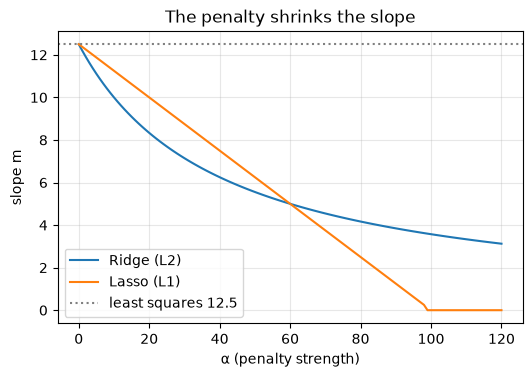

In [3]:
alphas = np.linspace(0, 120, 121)
plt.figure(figsize=(6, 3.8))
plt.plot(alphas, [Ridge(alpha=a).fit(X5, y).coef_[0] for a in alphas], label="Ridge (L2)")
plt.plot(alphas, [Lasso(alpha=max(a, 1e-6)).fit(X5, y).coef_[0] for a in alphas], label="Lasso (L1)")
plt.axhline(12.5, color="gray", ls=":", label="least squares 12.5")
plt.xlabel("α (penalty strength)"); plt.ylabel("slope m"); plt.legend(); plt.grid(alpha=.3)
plt.title("The penalty shrinks the slope"); plt.show()

Ridge shrinks smoothly and never quite reaches zero. Lasso shrinks in a straight line and hits **exactly zero** at α = 100. That difference is the whole reason Lasso is used for feature selection.

## 3. Lasso finds the noise

Twenty customers, three real features and **eight columns of random noise**. With 11 features and only 20 rows, ordinary least squares has plenty of room to fit noise.

In [4]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

cust20 = pd.read_csv(data_path("shopwave_customers_small.csv"))
X20 = cust20[["visits_last_month", "items_last_month", "days_since_last"]].copy()
rng = np.random.default_rng(7)
for i in range(1, 9):                       # eight columns of pure noise
    X20[f"noise_{i}"] = rng.normal(size=len(X20))
y20 = cust20["spend_next_month"]
X20.round(2).head()

,visits_last_month,items_last_month,days_since_last,noise_1,noise_2,noise_3,noise_4,noise_5,noise_6,noise_7,noise_8
0,2,2,55,0.00,-1.84,0.11,0.20,-0.43,-0.30,0.09,1.10
1,11,8,44,0.30,-0.24,0.06,-0.46,-0.30,-0.90,-0.59,-0.54
2,10,6,22,-0.27,-1.27,-1.23,0.13,0.35,0.16,-0.12,-0.05
3,7,6,58,-0.89,0.27,0.08,-1.19,-0.12,2.24,-2.00,-0.79
4,7,5,25,-0.45,0.16,1.36,-0.58,-0.20,-0.83,-1.13,-0.63


In [5]:
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, KFold
cv = KFold(5, shuffle=True, random_state=0)
models = {
    "least squares, all 11": (make_pipeline(StandardScaler(), LinearRegression()), X20.columns),
    "RidgeCV, all 11": (make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))), X20.columns),
    "LassoCV, all 11": (make_pipeline(StandardScaler(), LassoCV(cv=5, random_state=0, max_iter=50_000)), X20.columns),
    "least squares, 3 real only": (make_pipeline(StandardScaler(), LinearRegression()), X20.columns[:3]),
}
for name, (m, cols) in models.items():
    mae = -cross_val_score(m, X20[cols], y20, cv=cv, scoring="neg_mean_absolute_error").mean()
    print(f"{name:<28} CV MAE £{mae:.2f}")

least squares, all 11        CV MAE £14.71
RidgeCV, all 11              CV MAE £15.41


LassoCV, all 11              CV MAE £12.63
least squares, 3 real only   CV MAE £10.29


In [6]:
coefs = pd.DataFrame({name: m.fit(X20[cols], y20)[-1].coef_ for name, (m, cols) in list(models.items())[:3]},
                     index=X20.columns).round(1)
coefs

,"least squares, all 11","RidgeCV, all 11","LassoCV, all 11"
visits_last_month,62.1,44.7,50.3
items_last_month,4.3,19.6,13.6
days_since_last,-11.5,-14.1,-8.7
noise_1,8.5,6.7,0.0
noise_2,3.1,1.2,0.0
noise_3,2.6,2.2,0.0
noise_4,-3.8,-0.7,-0.0
noise_5,-8.6,-6.1,-0.0
noise_6,-2.2,-0.1,-0.0
noise_7,-7.0,-2.8,-0.0


Read the Lasso column: it kept the three real features and set seven of the eight noise columns to **exactly zero**. Least squares gave every noise column a coefficient, some as large as the real `days_since_last` effect. Lasso's CV error is the best of the three models that saw all 11 columns, though still above the "oracle" that was told which three are real.

Ridge did not help here: it shrinks everything a little but keeps every column, and with only 20 rows the noise columns still hurt.

## 4. Coefficient paths

How each coefficient changes as α grows. Read from right (no penalty) to left (strong penalty).

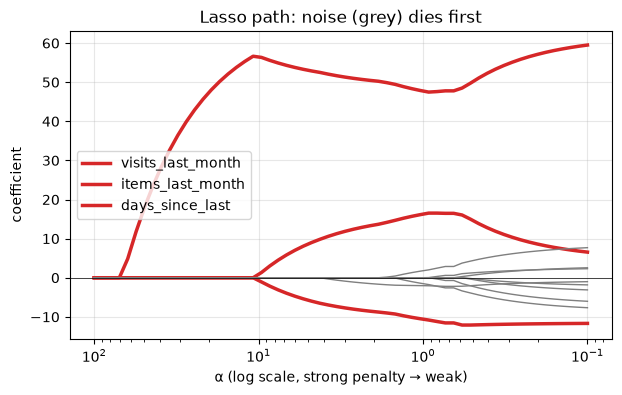

In [7]:
from sklearn.linear_model import lasso_path
Xs = StandardScaler().fit_transform(X20)
alphas_l, paths, _ = lasso_path(Xs, y20 - y20.mean(), alphas=np.logspace(-1, 2, 60))
plt.figure(figsize=(7, 4))
for name, path in zip(X20.columns, paths):
    plt.plot(alphas_l, path, color="tab:red" if not name.startswith("noise") else "tab:gray",
             lw=2.5 if not name.startswith("noise") else 1, label=None if name.startswith("noise") else name)
plt.xscale("log"); plt.gca().invert_xaxis(); plt.axhline(0, color="black", lw=.5)
plt.xlabel("α (log scale, strong penalty → weak)"); plt.ylabel("coefficient"); plt.legend()
plt.title("Lasso path: noise (grey) dies first"); plt.grid(alpha=.3); plt.show()

## 5. ElasticNet: a bit of both

ElasticNet mixes the two penalties. `l1_ratio=1` is Lasso, `0` is Ridge. Useful when several features are correlated: Lasso tends to keep one at random, ElasticNet keeps the group.

In [8]:
from sklearn.linear_model import ElasticNetCV
en = make_pipeline(StandardScaler(), ElasticNetCV(l1_ratio=[.2, .5, .8, 1.0], cv=5, random_state=0, max_iter=50_000))
mae = -cross_val_score(en, X20, y20, cv=cv, scoring="neg_mean_absolute_error").mean()
en.fit(X20, y20)
print(f"ElasticNetCV: CV MAE £{mae:.2f}, chosen l1_ratio {en[-1].l1_ratio_}, alpha {en[-1].alpha_:.3f}")

ElasticNetCV: CV MAE £12.63, chosen l1_ratio 1.0, alpha 1.921


Cross-validation chose `l1_ratio = 1.0`, i.e. pure Lasso, and the same error (£12.63). Sensible: here the truth really is "a few features matter, the rest are zero", which is exactly what L1 assumes.

## 6. Logistic regression is already regularised

`LogisticRegression` applies an L2 penalty **by default**. Its strength is set by `C`, which is the *inverse*: $C = 1/\alpha$. Small C = strong penalty. With `penalty="l1"` it behaves like Lasso.

Ten churn features, logged and scaled. Watch the number of features the model keeps as C shrinks:

In [9]:
# --- data helper: works locally and on Colab -------------------------------
from pathlib import Path
import urllib.request

def data_path(name):
    """Return a local path to data/<name>, downloading from GitHub on Colab."""
    for parent in [Path.cwd(), *Path.cwd().parents]:
        candidate = parent / "data" / name
        if candidate.exists():
            return candidate
    url = f"https://raw.githubusercontent.com/cloudops-one/training-ai-ml/main/data/{name}"
    dest = Path(name)
    if not dest.exists():
        urllib.request.urlretrieve(url, dest)
    return dest

import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

import sys
sys.path.insert(0, str(data_path("download.py").parent))
from download import load_retail

raw = load_retail("Year 2010-2011")                       # ~1 s after the first run
sales = raw[~raw["Invoice"].astype(str).str.startswith("C")]
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)].dropna(subset=["Customer ID"]).drop_duplicates()
sales = sales.assign(Revenue=sales["Quantity"] * sales["Price"])

cutoff = pd.Timestamp("2011-09-01")                       # features before, target after
past = sales[sales["InvoiceDate"] < cutoff]
future = sales[(sales["InvoiceDate"] >= cutoff) & (sales["InvoiceDate"] < "2011-12-01")]

cust = past.groupby("Customer ID").agg(orders=("Invoice", "nunique"), spend=("Revenue", "sum"),
                                       products=("StockCode", "nunique"),
                                       first_order=("InvoiceDate", "min"), last_order=("InvoiceDate", "max"))
cust["tenure_days"] = (cutoff - cust["first_order"]).dt.days
cust["days_since_last"] = (cutoff - cust["last_order"]).dt.days
future_spend = future.groupby("Customer ID")["Revenue"].sum().reindex(cust.index).fillna(0)
cust["churned"] = (future_spend == 0).astype(int)        # 1 = did not come back
cust = cust.drop(columns=["first_order", "last_order"])
features = ["orders", "spend", "products", "tenure_days", "days_since_last"]
print(f"{len(cust):,} customers, churn rate {cust['churned'].mean():.1%}")

cust["avg_basket"] = cust["spend"] / cust["orders"]
cust["orders_per_month"] = cust["orders"] / (cust["tenure_days"] / 30).clip(lower=1)
cust["log_spend"] = np.log1p(cust["spend"])
country = past.groupby("Customer ID")["Country"].agg(lambda s: s.mode()[0])
cust["country"] = country.reindex(cust.index)
cust["is_uk"] = (cust["country"] == "United Kingdom").astype(int)
weekend = past.assign(wk=past["InvoiceDate"].dt.dayofweek >= 5).groupby("Customer ID")["wk"].mean()
cust["share_weekend"] = weekend.reindex(cust.index)
autumn = past[past["InvoiceDate"] >= "2011-06-01"].groupby("Customer ID")["Invoice"].nunique()
cust["orders_last_3m"] = autumn.reindex(cust.index).fillna(0)

churn_cols = ["orders", "spend", "products", "tenure_days", "days_since_last", "avg_basket",
              "orders_per_month", "orders_last_3m", "is_uk", "share_weekend"]
Xc = cust[churn_cols].copy()
skewed = ["orders", "spend", "products", "avg_basket", "orders_per_month", "orders_last_3m"]
Xc[skewed] = np.log1p(Xc[skewed])
from sklearn.model_selection import train_test_split
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, cust["churned"], test_size=0.25,
                                                        random_state=42, stratify=cust["churned"])

3,317 customers, churn rate 43.6%


In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
skf = StratifiedKFold(5, shuffle=True, random_state=42)
for C in [0.001, 0.003, 0.01, 0.03, 0.1, 1, 10]:
    m = make_pipeline(StandardScaler(), LogisticRegression(penalty="l1", C=C, solver="liblinear"))
    auc = cross_val_score(m, Xc_train, yc_train, cv=skf, scoring="roc_auc").mean()
    kept = [c for c, w in zip(churn_cols, m.fit(Xc_train, yc_train)[-1].coef_[0]) if w != 0]
    print(f"C={C:<6} CV AUC {auc:.3f}   features kept {len(kept):>2}: {kept}")

C=0.001  CV AUC 0.500   features kept  0: []
C=0.003  CV AUC 0.722   features kept  1: ['orders']
C=0.01   CV AUC 0.741   features kept  5: ['orders', 'spend', 'products', 'days_since_last', 'orders_last_3m']


C=0.03   CV AUC 0.743   features kept  5: ['orders', 'spend', 'products', 'days_since_last', 'orders_last_3m']
C=0.1    CV AUC 0.742   features kept  8: ['orders', 'spend', 'products', 'tenure_days', 'days_since_last', 'orders_last_3m', 'is_uk', 'share_weekend']
C=1      CV AUC 0.742   features kept  9: ['orders', 'products', 'tenure_days', 'days_since_last', 'avg_basket', 'orders_per_month', 'orders_last_3m', 'is_uk', 'share_weekend']


C=10     CV AUC 0.742   features kept 10: ['orders', 'spend', 'products', 'tenure_days', 'days_since_last', 'avg_basket', 'orders_per_month', 'orders_last_3m', 'is_uk', 'share_weekend']


With a very strong penalty (C = 0.001) the model keeps nothing and is no better than a coin (AUC 0.5). At C = 0.01 it keeps **five** features (orders, spend, products, days since last, orders in the last 3 months) and reaches CV AUC 0.741, the same as all ten (0.742). That is useful beyond accuracy: a four-feature model is easier to explain to the retention team, cheaper to compute and has fewer things that can break.

## Quiz answers

1. Regularisation adds a penalty on the size of the coefficients to the loss, so the model prefers smaller, simpler fits. It reduces variance (overfitting) at the cost of a little bias.
2. Ridge (L2) penalises the sum of squared coefficients and shrinks them smoothly towards zero; Lasso (L1) penalises the sum of absolute values and can set coefficients exactly to zero.
3. $m = 500/(40 + 10) = 10$, $c = 100 - 10 × 6 = 40$.
4. Because the penalty depends on coefficient size, and coefficient size depends on the units of each feature. Without scaling, a feature measured in pounds gets a tiny coefficient and is barely penalised, while one measured in counts is penalised heavily.
5. Smaller. `C` is the inverse of the penalty strength; small C means a strong penalty.

**Next:** [04.P Mini-project: a leak-free churn pipeline](../project/)